10 giá trị BMI đầu tiên:
[24.36350297 38.76785766 33.29984855 29.9664621  18.90046601 18.89986301
 16.4520903  36.65440364 30.02787529 32.70181444]

10 nhãn đầu tiên:
[0 1 1 0 0 0 0 1 1 1]

BMI - Xác suất - Nhãn dự đoán
BMI = 27.34 | Xác suất = 0.5320 | Dự đoán = 1
BMI = 19.59 | Xác suất = 0.0223 | Dự đoán = 0
BMI = 30.19 | Xác suất = 0.8263 | Dự đoán = 1
BMI = 20.94 | Xác suất = 0.0433 | Dự đoán = 0
BMI = 15.17 | Xác suất = 0.0025 | Dự đoán = 0
BMI = 36.79 | Xác suất = 0.9925 | Dự đoán = 1
BMI = 39.67 | Xác suất = 0.9982 | Dự đoán = 1
BMI = 31.94 | Xác suất = 0.9199 | Dự đoán = 1
BMI = 31.13 | Xác suất = 0.8842 | Dự đoán = 1
BMI = 31.56 | Xác suất = 0.9048 | Dự đoán = 1

Độ chính xác (Accuracy): 0.9

Ma trận nhầm lẫn:
[[18  2]
 [ 2 18]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.90      0.90        20
           1       0.90      0.90      0.90        20

    accuracy                           0.90        40
   macro a

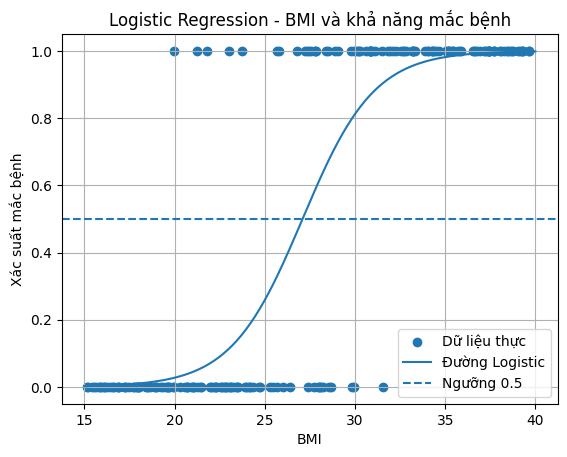

In [1]:
# BÀI 2: LOGISTIC REGRESSION - Dự đoán mắc bệnh theo BMI

import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import ( accuracy_score,
                             confusion_matrix, classification_report)

# 1. Tạo dữ liệu mẫu
np.random.seed(42)

# Tạo 200 giá trị BMI từ 15 đến 40
BMI = np.random.uniform(15, 40, 200)

# Xác suất mắc bệnh tăng khi BMI tăng
probability = 1 / (1 + np.exp(-(BMI - 27) / 2))

# Nhãn 0 hoặc 1 theo xác suất
mac_benh = np.random.binomial(1, probability)

# Chuyển BMI thành ma trận 2 chiều
X = BMI.reshape(-1, 1)
y = mac_benh

print("10 giá trị BMI đầu tiên:")
print(BMI[:10])
print("\n10 nhãn đầu tiên:")
print(y[:10])

# 2. Chia train/test
X_train, X_test, y_train, y_test = train_test_split(X, y,
    test_size=0.2, random_state=42)

# 3. Tạo mô hình
model = LogisticRegression()

# 4. Huấn luyện
model.fit(X_train, y_train)

# 5. Dự đoán
y_pred = model.predict(X_test)

# Xác suất mắc bệnh
y_probability = model.predict_proba(X_test)[:, 1]

print("\nBMI - Xác suất - Nhãn dự đoán")

for i in range(10):
    print(f"BMI = {X_test[i][0]:.2f} | "
        f"Xác suất = {y_probability[i]:.4f} | "
        f"Dự đoán = {y_pred[i]}")

# 6. Đánh giá
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
print("\nĐộ chính xác (Accuracy):", accuracy)
print("\nMa trận nhầm lẫn:")
print(cm)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 7. Dự đoán BMI mới
BMI_moi = np.array([
    [18],
    [22],
    [25],
    [28],
    [30],
    [35]
])

xac_suat = model.predict_proba(BMI_moi)[:, 1]
du_doan = model.predict(BMI_moi)

print("\nDỰ ĐOÁN BMI MỚI")

for bmi, p, label in zip(BMI_moi[:, 0], xac_suat, du_doan):
    print(f"BMI = {bmi} | "
        f"Xác suất mắc bệnh = {p:.4f} | "
        f"Nhãn = {label}")

# 8. Vẽ dường Logistic
BMI_range = np.linspace(15, 40, 300).reshape(-1, 1)
prob_range = model.predict_proba(BMI_range)[:, 1]
plt.scatter(BMI, y, label="Dữ liệu thực")
plt.plot(  BMI_range, prob_range, label="Đường Logistic")
plt.axhline(y=0.5, linestyle="--", label="Ngưỡng 0.5")

plt.xlabel("BMI")
plt.ylabel("Xác suất mắc bệnh")
plt.title("Logistic Regression - BMI và khả năng mắc bệnh")

plt.legend()
plt.grid()
plt.show()